In [1]:
import torch
print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
GPU available: True
GPU name: Tesla T4


In [2]:
import os
for root, dirs, files in os.walk("/kaggle/input"):
    print(root, "->", len(dirs), "folders,", len(files), "files")
    if root.count("/") > 5:
        break

/kaggle/input -> 1 folders, 0 files
/kaggle/input/datasets -> 1 folders, 0 files
/kaggle/input/datasets/iamsouravbanerjee -> 1 folders, 0 files
/kaggle/input/datasets/iamsouravbanerjee/indian-food-images-dataset -> 1 folders, 1 files
/kaggle/input/datasets/iamsouravbanerjee/indian-food-images-dataset/Indian Food Images -> 1 folders, 0 files


In [7]:
from pathlib import Path
import os

DATA_DIR = Path("/kaggle/input/datasets/iamsouravbanerjee/indian-food-images-dataset/Indian Food Images/Indian Food Images")

IMG_EXT = {".jpg", ".jpeg", ".png", ".webp"}

counts = {}
for cls in sorted(os.listdir(DATA_DIR)):
    p = DATA_DIR / cls
    if p.is_dir():
        counts[cls] = len([f for f in p.iterdir() if f.suffix.lower() in IMG_EXT])

print("Classes:", len(counts))
print("Total images:", sum(counts.values()))
print("\n10 smallest classes:")
for k, v in sorted(counts.items(), key=lambda x: x[1])[:10]:
    print(f"  {k}: {v}")
print("\n10 largest classes:")
for k, v in sorted(counts.items(), key=lambda x: -x[1])[:10]:
    print(f"  {k}: {v}")

Classes: 80
Total images: 4000

10 smallest classes:
  adhirasam: 50
  aloo_gobi: 50
  aloo_matar: 50
  aloo_methi: 50
  aloo_shimla_mirch: 50
  aloo_tikki: 50
  anarsa: 50
  ariselu: 50
  bandar_laddu: 50
  basundi: 50

10 largest classes:
  adhirasam: 50
  aloo_gobi: 50
  aloo_matar: 50
  aloo_methi: 50
  aloo_shimla_mirch: 50
  aloo_tikki: 50
  anarsa: 50
  ariselu: 50
  bandar_laddu: 50
  basundi: 50


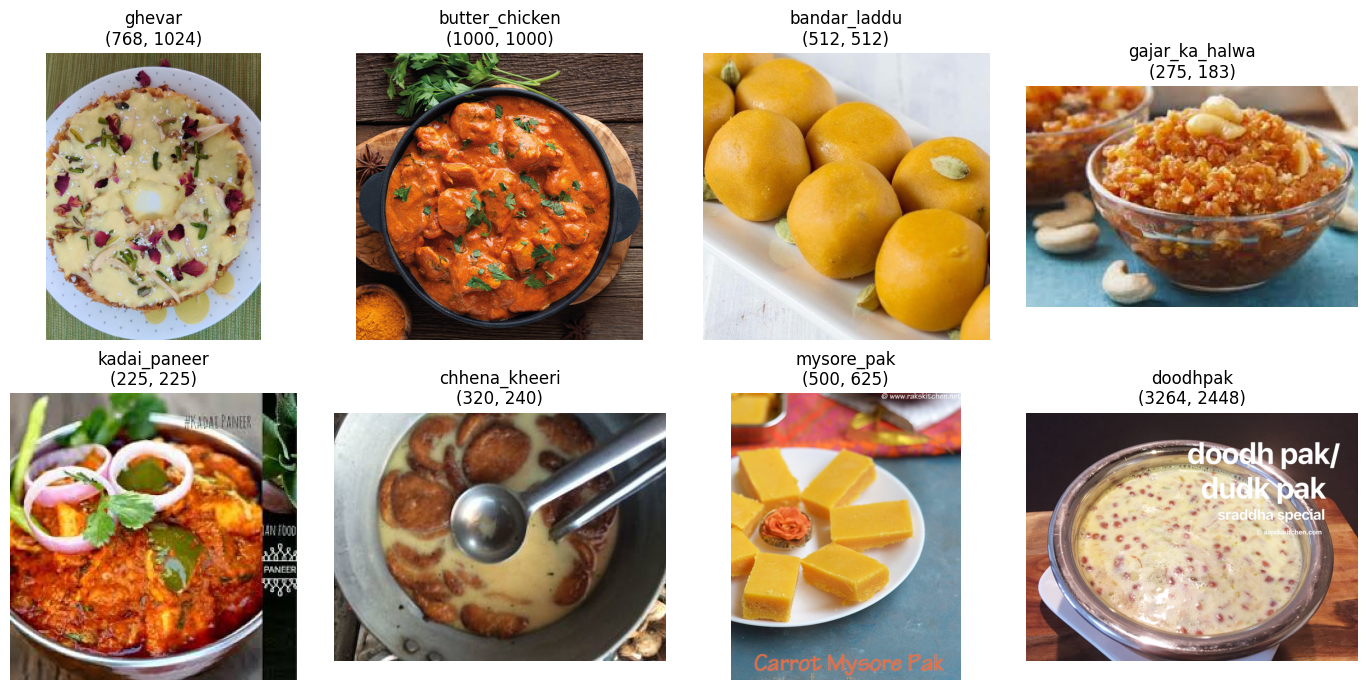

In [9]:
import random
import matplotlib.pyplot as plt
from PIL import Image

classes = list(counts.keys())
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax in axes.flat:
    cls = random.choice(classes)
    files = [f for f in (DATA_DIR / cls).iterdir() if f.suffix.lower() in IMG_EXT]
    img = Image.open(random.choice(files)).convert("RGB")
    ax.imshow(img)
    ax.set_title(f"{cls}\n{img.size}")
    ax.axis("off")
plt.tight_layout()
plt.show()

In [10]:
import random
from pathlib import Path

random.seed(42)  # makes the split reproducible

train_files, val_files, test_files = [], [], []
class_names = sorted(counts.keys())
class_to_idx = {c: i for i, c in enumerate(class_names)}

for cls in class_names:
    files = sorted([f for f in (DATA_DIR / cls).iterdir() if f.suffix.lower() in IMG_EXT])
    random.shuffle(files)
    pairs = [(f, class_to_idx[cls]) for f in files]
    train_files += pairs[:35]
    val_files   += pairs[35:42]
    test_files  += pairs[42:50]

print("Train:", len(train_files), "Val:", len(val_files), "Test:", len(test_files))

Train: 2800 Val: 560 Test: 640


In [11]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

class FoodDataset(Dataset):
    def __init__(self, items, transform):
        self.items = items
        self.transform = transform
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        path, label = self.items[i]
        img = Image.open(path).convert("RGB")
        return self.transform(img), label

mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]  # ImageNet stats

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(0.2, 0.2, 0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
eval_tf = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

train_ds = FoodDataset(train_files, train_tf)
val_ds   = FoodDataset(val_files, eval_tf)
test_ds  = FoodDataset(test_files, eval_tf)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True,  num_workers=2)
val_loader   = DataLoader(val_ds,   batch_size=32, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_ds,  batch_size=32, shuffle=False, num_workers=2)

In [12]:
images, labels = next(iter(train_loader))
print("Batch shape:", images.shape)   # expect [32, 3, 224, 224]
print("Labels:", labels[:8].tolist())
print("Names:", [class_names[l] for l in labels[:8]])

Batch shape: torch.Size([32, 3, 224, 224])
Labels: [44, 6, 31, 72, 28, 70, 35, 61]
Names: ['karela_bharta', 'anarsa', 'dum_aloo', 'shankarpali', 'dharwad_pedha', 'rasgulla', 'gulab_jamun', 'paneer_butter_masala']


In [13]:
import torch.nn as nn
from torchvision import models

device = torch.device("cuda")

model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Freeze all pretrained layers
for p in model.parameters():
    p.requires_grad = False

# Replace final layer (new layers are trainable by default)
model.fc = nn.Linear(model.fc.in_features, len(class_names))
model = model.to(device)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"Trainable params: {trainable:,} / {total:,}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 168MB/s] 


Trainable params: 41,040 / 11,217,552


In [14]:
def run_epoch(loader, train=False):
    model.train(train)
    total_loss, correct, n = 0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

In [15]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.fc.parameters(), lr=1e-3)

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

for epoch in range(10):
    tl, ta = run_epoch(train_loader, train=True)
    vl, va = run_epoch(val_loader, train=False)
    history["train_loss"].append(tl); history["val_loss"].append(vl)
    history["train_acc"].append(ta);  history["val_acc"].append(va)
    print(f"Epoch {epoch+1:2d} | train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f}")

Epoch  1 | train loss 4.045 acc 0.100 | val loss 3.373 acc 0.237
Epoch  2 | train loss 2.887 acc 0.347 | val loss 2.765 acc 0.352
Epoch  3 | train loss 2.302 acc 0.494 | val loss 2.440 acc 0.391
Epoch  4 | train loss 1.941 acc 0.574 | val loss 2.308 acc 0.425
Epoch  5 | train loss 1.730 acc 0.602 | val loss 2.198 acc 0.418
Epoch  6 | train loss 1.542 acc 0.643 | val loss 2.122 acc 0.450
Epoch  7 | train loss 1.383 acc 0.673 | val loss 2.100 acc 0.445
Epoch  8 | train loss 1.306 acc 0.675 | val loss 2.026 acc 0.455
Epoch  9 | train loss 1.231 acc 0.708 | val loss 2.011 acc 0.466
Epoch 10 | train loss 1.137 acc 0.733 | val loss 1.969 acc 0.495


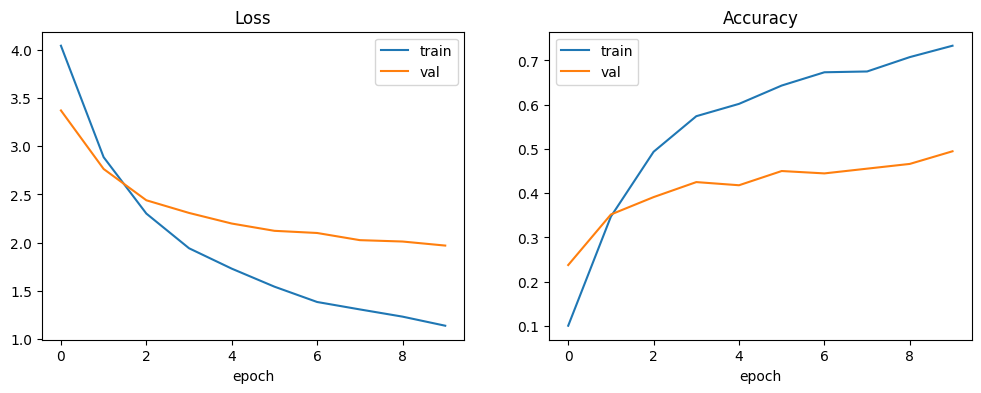

In [16]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history["train_loss"], label="train"); ax[0].plot(history["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(history["train_acc"], label="train"); ax[1].plot(history["val_acc"], label="val")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.show()

In [17]:
def build_resnet18():
    m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    for p in m.parameters():
        p.requires_grad = False
    for block in [m.layer3, m.layer4]:
        for p in block.parameters():
            p.requires_grad = True
    m.fc = nn.Linear(m.fc.in_features, len(class_names))
    return m.to(device)

model = build_resnet18()
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable params: {trainable:,}")

Trainable params: 10,534,480


In [18]:
EPOCHS = 15
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

backbone_params = list(model.layer3.parameters()) + list(model.layer4.parameters())
optimizer = torch.optim.AdamW([
    {"params": backbone_params,        "lr": 1e-4},
    {"params": model.fc.parameters(),  "lr": 1e-3},
], weight_decay=1e-2)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

history2 = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val = 0

for epoch in range(EPOCHS):
    tl, ta = run_epoch(train_loader, train=True)
    vl, va = run_epoch(val_loader, train=False)
    scheduler.step()
    for k, v in zip(history2, [tl, vl, ta, va]):
        history2[k].append(v)
    if va > best_val:
        best_val = va
        torch.save(model.state_dict(), "best_resnet18.pt")
    print(f"Epoch {epoch+1:2d} | train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f}")

print("Best val acc:", best_val)

Epoch  1 | train loss 3.453 acc 0.242 | val loss 2.541 acc 0.480
Epoch  2 | train loss 2.000 acc 0.644 | val loss 2.155 acc 0.575
Epoch  3 | train loss 1.501 acc 0.817 | val loss 2.044 acc 0.625
Epoch  4 | train loss 1.244 acc 0.905 | val loss 2.026 acc 0.634
Epoch  5 | train loss 1.097 acc 0.949 | val loss 1.941 acc 0.652
Epoch  6 | train loss 1.004 acc 0.973 | val loss 1.950 acc 0.654
Epoch  7 | train loss 0.949 acc 0.985 | val loss 1.929 acc 0.664
Epoch  8 | train loss 0.923 acc 0.988 | val loss 1.921 acc 0.662
Epoch  9 | train loss 0.905 acc 0.991 | val loss 1.919 acc 0.659
Epoch 10 | train loss 0.892 acc 0.991 | val loss 1.933 acc 0.670
Epoch 11 | train loss 0.882 acc 0.993 | val loss 1.931 acc 0.662
Epoch 12 | train loss 0.874 acc 0.994 | val loss 1.932 acc 0.666
Epoch 13 | train loss 0.869 acc 0.994 | val loss 1.931 acc 0.679
Epoch 14 | train loss 0.865 acc 0.995 | val loss 1.930 acc 0.662
Epoch 15 | train loss 0.863 acc 0.994 | val loss 1.937 acc 0.670
Best val acc: 0.678571428

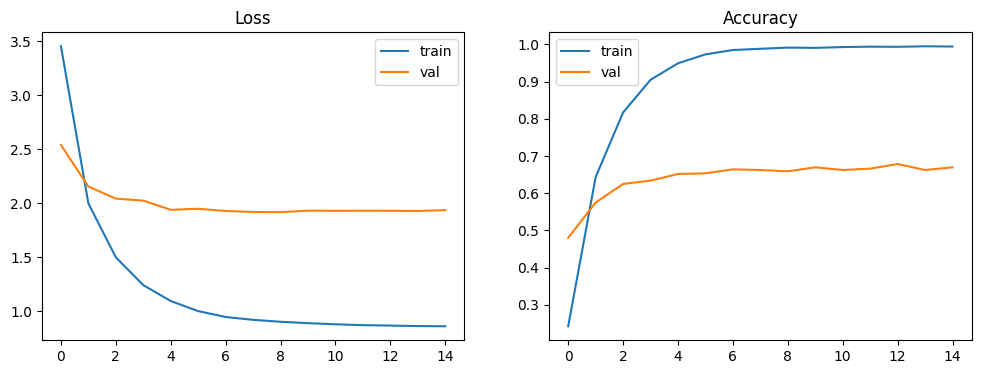

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history2["train_loss"], label="train"); ax[0].plot(history2["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(history2["train_acc"], label="train"); ax[1].plot(history2["val_acc"], label="val")
ax[1].set_title("Accuracy"); ax[1].legend()
plt.show()

stronger augmentation

We have few images, so we make each one look different every epoch. We keep the same model so we can see what augmentation alone does. We’ll add:

TrivialAugmentWide: a random strong transform on each image (rotation, shear, color, contrast, and so on)
RandomErasing: blocks out a random patch, so the model can’t rely on one watermark or one detail (useful for the watermark shortcut we noticed earlier)

In [23]:
train_tf2 = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.5, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.TrivialAugmentWide(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
    transforms.RandomErasing(p=0.25),
])

train_ds2 = FoodDataset(train_files, train_tf2)
train_loader2 = DataLoader(train_ds2, batch_size=32, shuffle=True, num_workers=2)

In [24]:
model = build_resnet18()

EPOCHS = 20
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
backbone_params = list(model.layer3.parameters()) + list(model.layer4.parameters())
optimizer = torch.optim.AdamW([
    {"params": backbone_params,       "lr": 1e-4},
    {"params": model.fc.parameters(), "lr": 1e-3},
], weight_decay=1e-2)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

history3 = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val = 0

for epoch in range(EPOCHS):
    tl, ta = run_epoch(train_loader2, train=True)   # note: train_loader2
    vl, va = run_epoch(val_loader, train=False)
    scheduler.step()
    for k, v in zip(history3, [tl, vl, ta, va]):
        history3[k].append(v)
    if va > best_val:
        best_val = va
        torch.save(model.state_dict(), "best_resnet18_aug.pt")
    print(f"Epoch {epoch+1:2d} | train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f}")

print("Best val acc:", best_val)

Epoch  1 | train loss 3.750 acc 0.169 | val loss 2.660 acc 0.388
Epoch  2 | train loss 2.545 acc 0.459 | val loss 2.259 acc 0.559
Epoch  3 | train loss 2.146 acc 0.588 | val loss 2.103 acc 0.570
Epoch  4 | train loss 1.971 acc 0.639 | val loss 2.040 acc 0.621
Epoch  5 | train loss 1.760 acc 0.702 | val loss 2.020 acc 0.616
Epoch  6 | train loss 1.684 acc 0.740 | val loss 1.966 acc 0.637
Epoch  7 | train loss 1.575 acc 0.781 | val loss 1.981 acc 0.618
Epoch  8 | train loss 1.483 acc 0.811 | val loss 1.945 acc 0.645
Epoch  9 | train loss 1.439 acc 0.832 | val loss 1.905 acc 0.666
Epoch 10 | train loss 1.403 acc 0.838 | val loss 1.897 acc 0.677
Epoch 11 | train loss 1.350 acc 0.863 | val loss 1.890 acc 0.664
Epoch 12 | train loss 1.308 acc 0.880 | val loss 1.891 acc 0.680
Epoch 13 | train loss 1.264 acc 0.890 | val loss 1.861 acc 0.684
Epoch 14 | train loss 1.260 acc 0.892 | val loss 1.844 acc 0.684
Epoch 15 | train loss 1.248 acc 0.896 | val loss 1.824 acc 0.691
Epoch 16 | train loss 1.2

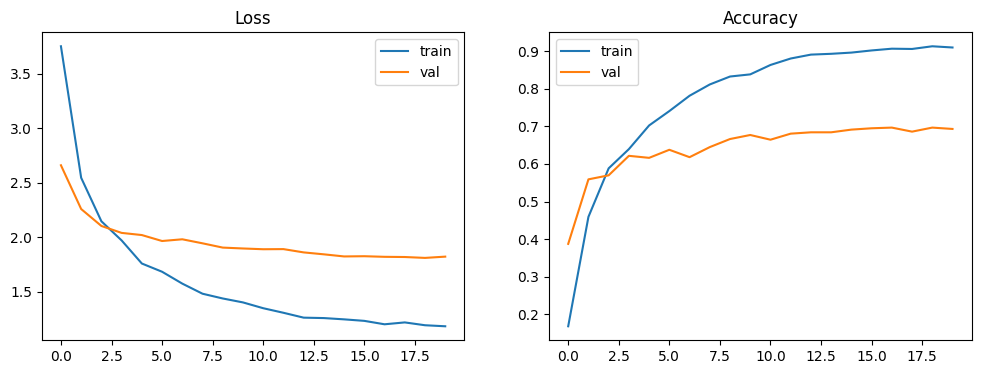

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history3["train_loss"], label="train"); ax[0].plot(history3["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(history3["train_acc"], label="train"); ax[1].plot(history3["val_acc"], label="val")
ax[1].set_title("Accuracy"); ax[1].legend()
plt.show()

In [26]:
def build_effnet():
    m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
    for p in m.parameters():
        p.requires_grad = False
    # unfreeze the last 3 blocks of the backbone
    for block in m.features[-3:]:
        for p in block.parameters():
            p.requires_grad = True
    in_f = m.classifier[1].in_features
    m.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(in_f, len(class_names)))
    return m.to(device)

model = build_effnet()
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable params: {trainable:,}")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 127MB/s] 


Trainable params: 3,258,220


In [27]:
EPOCHS = 20
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

backbone_params = [p for b in model.features[-3:] for p in b.parameters()]
optimizer = torch.optim.AdamW([
    {"params": backbone_params,           "lr": 2e-4},
    {"params": model.classifier.parameters(), "lr": 1e-3},
], weight_decay=1e-2)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

history4 = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val = 0

for epoch in range(EPOCHS):
    tl, ta = run_epoch(train_loader2, train=True)
    vl, va = run_epoch(val_loader, train=False)
    scheduler.step()
    for k, v in zip(history4, [tl, vl, ta, va]):
        history4[k].append(v)
    if va > best_val:
        best_val = va
        torch.save(model.state_dict(), "best_effnet_b0.pt")
    print(f"Epoch {epoch+1:2d} | train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f}")

print("Best val acc:", best_val)

Epoch  1 | train loss 3.730 acc 0.189 | val loss 2.512 acc 0.498
Epoch  2 | train loss 2.421 acc 0.505 | val loss 2.090 acc 0.571
Epoch  3 | train loss 2.021 acc 0.619 | val loss 1.934 acc 0.648
Epoch  4 | train loss 1.795 acc 0.692 | val loss 1.889 acc 0.670
Epoch  5 | train loss 1.673 acc 0.742 | val loss 1.843 acc 0.675
Epoch  6 | train loss 1.567 acc 0.771 | val loss 1.843 acc 0.668
Epoch  7 | train loss 1.484 acc 0.801 | val loss 1.802 acc 0.677
Epoch  8 | train loss 1.444 acc 0.817 | val loss 1.797 acc 0.688
Epoch  9 | train loss 1.372 acc 0.850 | val loss 1.787 acc 0.700
Epoch 10 | train loss 1.324 acc 0.868 | val loss 1.796 acc 0.696
Epoch 11 | train loss 1.309 acc 0.865 | val loss 1.783 acc 0.704
Epoch 12 | train loss 1.294 acc 0.873 | val loss 1.782 acc 0.714
Epoch 13 | train loss 1.256 acc 0.889 | val loss 1.775 acc 0.707
Epoch 14 | train loss 1.236 acc 0.897 | val loss 1.764 acc 0.705
Epoch 15 | train loss 1.244 acc 0.896 | val loss 1.747 acc 0.718
Epoch 16 | train loss 1.2

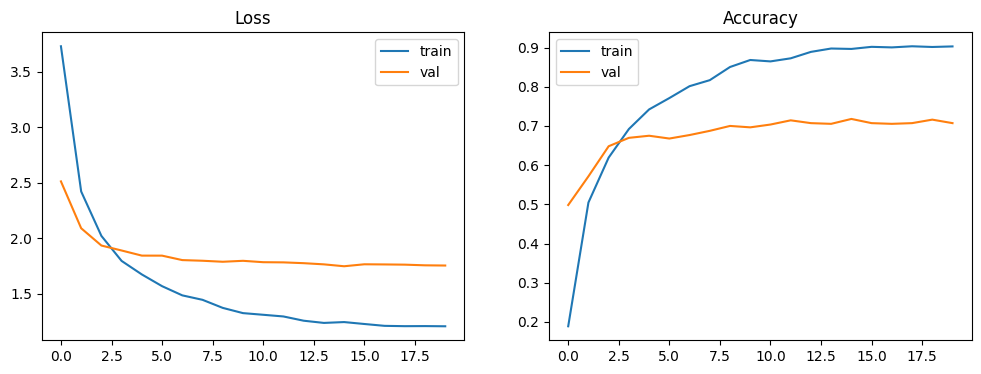

In [28]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history4["train_loss"], label="train"); ax[0].plot(history4["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(history4["train_acc"], label="train"); ax[1].plot(history4["val_acc"], label="val")
ax[1].set_title("Accuracy"); ax[1].legend()
plt.show()

In [30]:
# Predict on validation set
model = build_effnet()
model.load_state_dict(torch.load("best_effnet_b0.pt"))
model.eval()

all_preds, all_labels, all_conf = [], [], []
with torch.no_grad():
    for x, y in val_loader:
        out = model(x.to(device))
        probs = out.softmax(1)
        conf, pred = probs.max(1)
        all_preds += pred.cpu().tolist()
        all_labels += y.tolist()
        all_conf += conf.cpu().tolist()

import numpy as np
all_preds, all_labels = np.array(all_preds), np.array(all_labels)
print("Val accuracy:", (all_preds == all_labels).mean())

Val accuracy: 0.7178571428571429


In [31]:
#Which classes are hardest, and what they get confused with
from collections import Counter

per_class = {}
for i, name in enumerate(class_names):
    mask = all_labels == i
    per_class[name] = (all_preds[mask] == i).mean()

print("10 WORST classes:")
for name, acc in sorted(per_class.items(), key=lambda x: x[1])[:10]:
    i = class_to_idx[name]
    wrong = Counter(class_names[p] for p in all_preds[all_labels == i] if p != i)
    print(f"  {name}: {acc:.0%}  | confused with: {wrong.most_common(2)}")

print("\n10 BEST classes:")
for name, acc in sorted(per_class.items(), key=lambda x: -x[1])[:10]:
    print(f"  {name}: {acc:.0%}")

10 WORST classes:
  adhirasam: 14%  | confused with: [('ariselu', 4), ('unni_appam', 1)]
  doodhpak: 14%  | confused with: [('sheer_korma', 2), ('dal_tadka', 1)]
  ledikeni: 14%  | confused with: [('gulab_jamun', 2), ('lyangcha', 2)]
  chicken_tikka: 29%  | confused with: [('butter_chicken', 2), ('aloo_tikki', 1)]
  chicken_tikka_masala: 29%  | confused with: [('butter_chicken', 3), ('kadai_paneer', 1)]
  kachori: 29%  | confused with: [('poornalu', 2), ('dum_aloo', 1)]
  basundi: 43%  | confused with: [('phirni', 2), ('doodhpak', 1)]
  butter_chicken: 43%  | confused with: [('chicken_tikka_masala', 3), ('aloo_gobi', 1)]
  cham_cham: 43%  | confused with: [('shrikhand', 1), ('kalakand', 1)]
  chhena_kheeri: 43%  | confused with: [('pithe', 1), ('unni_appam', 1)]

10 BEST classes:
  bhatura: 100%
  boondi: 100%
  chicken_razala: 100%
  dal_makhani: 100%
  dharwad_pedha: 100%
  jalebi: 100%
  kofta: 100%
  lassi: 100%
  makki_di_roti_sarson_da_saag: 100%
  palak_paneer: 100%


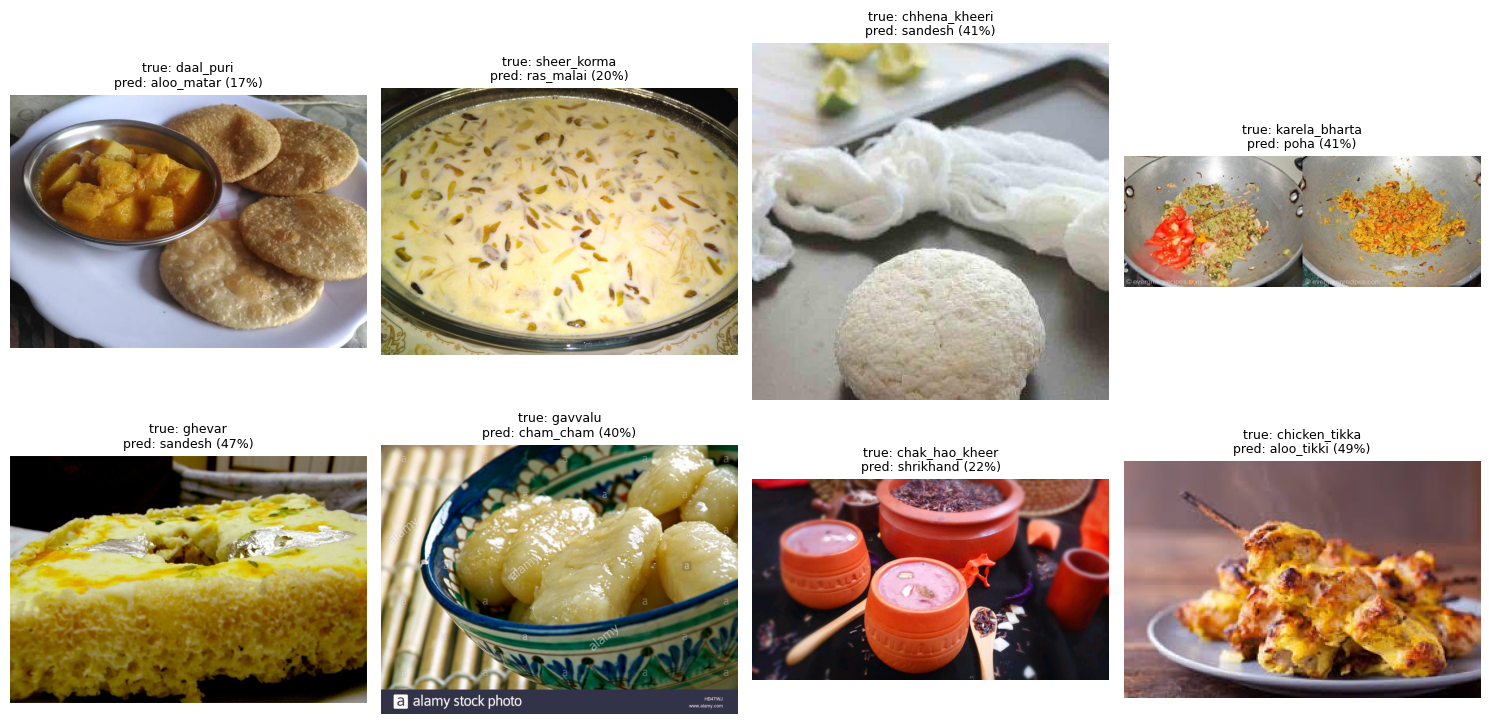

In [33]:
# Look at wrong predictions
wrong_idx = [i for i in range(len(all_preds)) if all_preds[i] != all_labels[i]]
fig, axes = plt.subplots(2, 4, figsize=(15, 8))
for ax, i in zip(axes.flat, random.sample(wrong_idx, 8)):
    path, _ = val_files[i]
    ax.imshow(Image.open(path).convert("RGB"))
    ax.set_title(f"true: {class_names[all_labels[i]]}\npred: {class_names[all_preds[i]]} ({all_conf[i]:.0%})", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [35]:
#Test set evaluation
model = build_effnet()
model.load_state_dict(torch.load("best_effnet_b0.pt"))
model.eval()

top1, top3, n = 0, 0, 0
with torch.no_grad():
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        out = model(x)
        top3_preds = out.topk(3, dim=1).indices
        top1 += (top3_preds[:, 0] == y).sum().item()
        top3 += (top3_preds == y.unsqueeze(1)).any(dim=1).sum().item()
        n += x.size(0)

print(f"TEST top-1 accuracy: {top1/n:.3f}")
print(f"TEST top-3 accuracy: {top3/n:.3f}")

TEST top-1 accuracy: 0.700
TEST top-3 accuracy: 0.881


In [36]:
# Save the model and class names
import json

torch.save(model.state_dict(), "food_classifier.pt")
with open("class_names.json", "w") as f:
    json.dump(class_names, f)
print("Saved.")

Saved.


In [37]:
!pip install -q gradio

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.


In [38]:
import gradio as gr
print("Gradio version:", gr.__version__)

Gradio version: 6.30.0


In [39]:
import gradio as gr

model.eval()

def predict(img):
    if img is None:
        return {}
    x = eval_tf(img.convert("RGB")).unsqueeze(0).to(device)
    with torch.no_grad():
        probs = model(x).softmax(1)[0]
    top = probs.topk(3)
    return {class_names[i]: float(p) for p, i in zip(top.values, top.indices)}

demo = gr.Interface(
    fn=predict,
    inputs=gr.Image(type="pil", label="Upload a food photo"),
    outputs=gr.Label(num_top_classes=3, label="Top 3 predictions"),
    title="Indian Food Classifier",
    description="EfficientNet-B0 fine-tuned on 80 Indian dishes (70% top-1, 88% top-3 on held-out test images).",
)
demo.launch(share=True)

* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://7d9617b7acfcb70093.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
